In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

csv_path = Path("data") / "Walmart_Sales.csv"

sales = pd.read_csv(csv_path)
sales["Date"] = pd.to_datetime(sales["Date"], format="%d-%m-%Y")

print(f"Rows: {len(sales):,}")
print(f"Stores: {sales['Store'].nunique()}")
print(f"Date range: {sales['Date'].min():%Y-%m-%d} to {sales['Date'].max():%Y-%m-%d}")
print(f"Missing values: {sales.isna().sum().sum()}")
print(f"Duplicate store-week records: {sales.duplicated(['Store', 'Date']).sum()}")

Rows: 6,435
Stores: 45
Date range: 2010-02-05 to 2012-10-26
Missing values: 0
Duplicate store-week records: 0


In [6]:
monthly_sales = (
    sales.groupby(sales["Date"].dt.to_period("M"))["Weekly_Sales"]
    .sum()
    .sort_index()
)

store_sales = (
    sales.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(f"Highest-sales month: {monthly_sales.idxmax()}")
print(f"Sales that month: {monthly_sales.max():,.2f}")
print(f"Highest-sales store: {store_sales.idxmax()}")
print(f"Total sales for that store: {store_sales.max():,.2f}")

Highest-sales month: 2010-12
Sales that month: 288,760,532.72
Highest-sales store: 20
Total sales for that store: 301,397,792.46


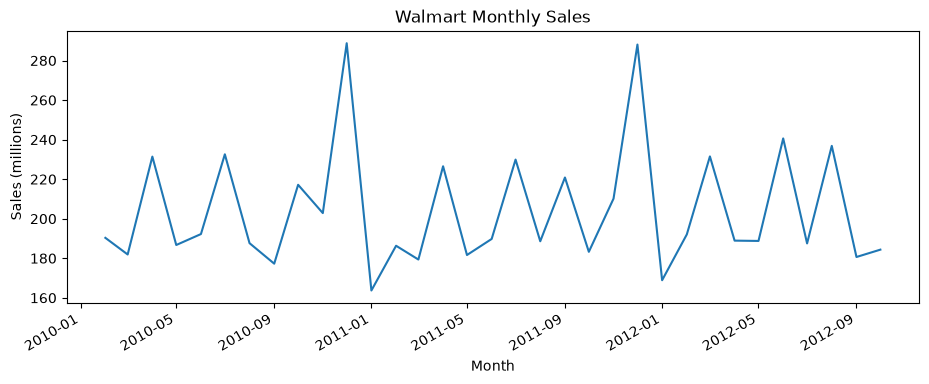

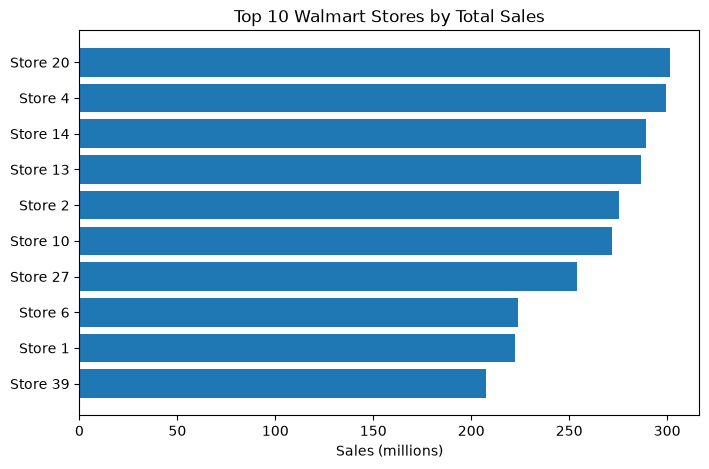

In [7]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_sales.index.to_timestamp(), monthly_sales / 1_000_000)
ax.set(title="Walmart Monthly Sales", xlabel="Month", ylabel="Sales (millions)")
fig.autofmt_xdate()
fig.savefig(output_dir / "monthly_sales.png", dpi=150, bbox_inches="tight")
plt.show()

top_stores = store_sales.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"Store {store}" for store in top_stores.index], top_stores / 1_000_000)
ax.set(title="Top 10 Walmart Stores by Total Sales", xlabel="Sales (millions)")
fig.savefig(output_dir / "top_10_stores.png", dpi=150, bbox_inches="tight")
plt.show()